# MetricSuite Tutorial: Load, Cluster-Permutation Test, and Plot

`mindmap.metric.MetricSuite` manages the metrics from a study: registering them,
saving/loading, plotting, and computing statistics, all from one object. This
notebook walks through the three things you'll do with a saved study most often:

1. **Load** a previously saved `MetricSuite` from disk.
2. **Plot** an outcome across a swept coordinate (`correlation_pp` vs. SNR).
3. **Test** where two methods differ significantly along that sweep, via a
   region-as-subject cluster-permutation test.

Data: `noisesweep/`, a `MetricSuite` saved next to this notebook -- the noise/SNR
sweep study built by `tutorials/analysis/inverse/inverse-noisesweep.ipynb` (5 inverse
methods x 6 SNR levels x 8 regions x 5 repetitions). See that notebook for how the
study was generated and why each metric is tagged with `method`, `snr`, *and*
`region`.

## 📦 - Load

`MetricSuite.load(folder)` reads back a folder written by `.save()` (a `data.npz` +
`meta.json` pair) -- cheap even for studies with thousands of registered entries, see
`MetricSuite.load`'s docstring for why. `MetricSuite.peek(folder)` is even cheaper: it
reads only `meta.json`, useful for a quick look before committing to a full load
(e.g. when scanning many per-subject folders).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import mindmap as mm

print(mm.metric.MetricSuite.peek("noisesweep"))

{'name': 'Noise/SNR sweep simf10-noisesweep', 'group_name': 'Label', 'subject': None, 'metadata': {}, 'saved_at': '2026-07-22T13:32:04.279576', 'n_entries': 6000, 'metrics': ['ap_hrp', 'ap_pp', 'correlation_hrp', 'correlation_pp', 'localization_error_hrp'], 'labels': ['cset', 'dspm', 'mne', 'sloreta', 'wcset']}


In [2]:
suite = mm.metric.MetricSuite.load("noisesweep")
suite.name

'Noise/SNR sweep simf10-noisesweep'

## 🔍 - Inspecting the suite

`.summary()` gives a quick per-`(Metric, Label)` overview (mean/std/count); `.dataframe`
materializes the full long-format table on demand (kept as raw arrays internally until
you actually need it -- see `MetricSuite.register`'s docstring). Every row here carries
`method` (== `Label`, the wCSET/CSET/dSPM/MNE/sLORETA method), `snr`, and `region` (the
brain region a run's source was simulated in) -- `region` is what makes the
cluster-permutation test below valid, since repetitions aren't matched across SNR levels
but the same physical region is.

In [3]:
suite.summary()

mean        std  count
Metric                 Label                               
ap_hrp                 cset      0.508363   0.138886    240
                       dspm      0.464227   0.107880    240
                       mne       0.444164   0.114445    240
                       sloreta   0.467920   0.109886    240
                       wcset     0.554656   0.145572    240
ap_pp                  cset      0.853204   0.088905    240
                       dspm      0.827892   0.096906    240
                       mne       0.824706   0.091864    240
                       sloreta   0.828547   0.095140    240
                       wcset     0.876809   0.084058    240
correlation_hrp        cset      0.300609   0.177054    240
                       dspm      0.113105   0.075703    240
                       mne       0.118422   0.068815    240
                       sloreta   0.117517   0.070752    240
                       wcset     0.525524   0.224172    240
correlation_pp         cset      0.374315   0.193519    240
                       dspm      0.131371   0.064286    240
                       mne       0.150565   0.067997    240
                       sloreta   0.141993   0.063754    240
                       wcset     0.608621   0.198126    240
localization_error_hrp cset     25.620380  28.299440    240
                       dspm     20.348069  19.205351    240
                       mne      51.787693  40.488742    240
                       sloreta  31.491419  32.575133    240
                       wcset    19.171310  30.223741    240

In [4]:
df = suite.dataframe
print(df.columns.tolist())
print(f"{df['region'].nunique()} regions, SNR levels {sorted(df['snr'].unique())}, methods {sorted(df['Label'].unique())}")
df.head()

['Label', 'Metric', 'Value', 'method', 'snr', 'region']
8 regions, SNR levels [np.float64(1.0), np.float64(2.0), np.float64(5.0), np.float64(10.0), np.float64(20.0), np.float64(50.0)], methods ['cset', 'dspm', 'mne', 'sloreta', 'wcset']


,Label,Metric,Value,method,snr,region
0,wcset,correlation_hrp,0.707364,wcset,50.0,ctx-rh-rostralanteriorcingulate_1
1,wcset,correlation_pp,0.833910,wcset,50.0,ctx-rh-rostralanteriorcingulate_1
2,wcset,localization_error_hrp,12.522372,wcset,50.0,ctx-rh-rostralanteriorcingulate_1
3,wcset,ap_hrp,0.724400,wcset,50.0,ctx-rh-rostralanteriorcingulate_1
4,wcset,ap_pp,0.927423,wcset,50.0,ctx-rh-rostralanteriorcingulate_1


## 📈 - Overview: correlation_pp across all methods

Before drilling into a pairwise test, `.plot()` gives the full picture -- one line per
method, median +/- 50% percentile interval across the 8 regions x 5 repetitions at each
SNR level (same aggregation convention as `inverse-noisesweep.ipynb`). wCSET
(this project's method) is visibly and consistently above the others, but "visibly
above" isn't the same as "significantly above at every SNR level" -- that's what the
cluster-permutation test below actually answers.

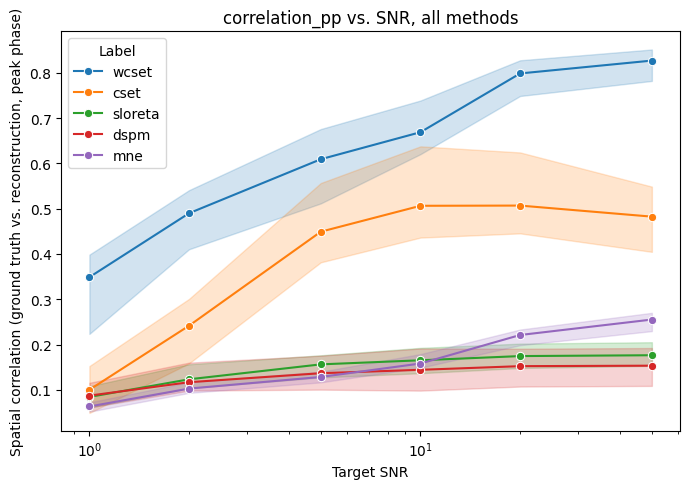

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
suite.plot(
    metric="correlation_pp", x="snr", kind="line",
    estimator="median", errorbar=("pi", 50), marker="o",
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("Target SNR")
ax.set_ylabel("Spatial correlation (ground truth vs. reconstruction, peak phase)")
ax.set_title("correlation_pp vs. SNR, all methods")
fig.tight_layout()

## 🧪 - Cluster-permutation test: where does wCSET win?

`MetricSuite.cluster_permutation` wraps `mne.stats.permutation_cluster_1samp_test`
(via `mindmap.analysis.stats.cluster_permutation_mne`) to answer a more precise
question than "is there an overall difference": **at which contiguous SNR levels is
wCSET significantly better than a given competitor?** Region plays the role of
"subject" (the standard Maris & Oostenveld cluster-permutation design, with SNR level
playing the role of "time") -- same design as
`tutorials/analysis/simulations/pilot_noise_cluster_permutation.ipynb`, now expressed
through the `MetricSuite` API instead of a hand-rolled sign-flip loop.

- `subject_col="region"`: repeated-measures unit. Repetitions can't serve this role --
  each `(region, snr, repetition)` run drew its own independent seed (including the
  signal-jitter, not just the noise), so reps aren't matched across SNR levels. Region
  is: it's the same physical region at every SNR level.
- `coord_order=[50, 20, 10, 5, 2, 1]`: explicit descending order, since "decreasing SNR"
  is the meaningful contiguity direction (increasing noise), not numeric ascending order.
- `higher_is_better=True` (default): `correlation_pp` is better when higher, so a
  positive result means "wCSET wins" -- matches the sign convention used throughout
  this codebase's cluster-permutation tooling.
- `plot=True`: also draws the reference-vs-competitor line plot with each significant
  cluster's SNR range shaded (green = wCSET better, red = competitor better).

Below: wCSET vs. CSET, the strongest competitor -- an interesting case, since (unlike
the other three) the two methods aren't significantly different across the whole sweep,
only at its two ends.

,snr_start,snr_end,mass,sign,p_value,significant
0,50,10,15.993957,1,0.015625,True
1,2,1,17.005922,1,0.015625,True


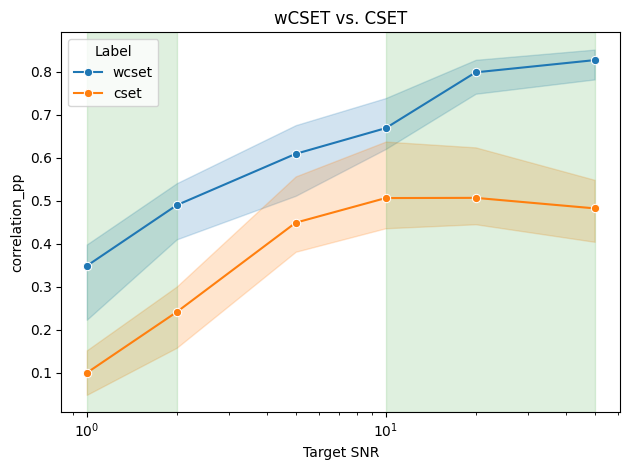

In [6]:
result, fig, ax = suite.cluster_permutation(
    metric="correlation_pp", coord="snr", reference="wcset", competitor="cset",
    subject_col="region", coord_order=[50, 20, 10, 5, 2, 1],
    n_permutations=3000, seed=0,
    plot=True, estimator="median", errorbar=("pi", 50), marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("Target SNR")
ax.set_ylabel("correlation_pp")
ax.set_title("wCSET vs. CSET")
fig.tight_layout()

result["clusters"]

Two significant clusters, in opposite directions of the same overall trend: wCSET
wins at the high-SNR end (50-10) and again at the low-SNR end (2-1), with SNR=5 not
distinguishing the two methods. `result` also carries `t_obs` (the per-SNR-level
observed t-statistic) and `diff` (the raw region x SNR paired-difference matrix, if you
want to build your own summary curve instead of the shaded plot above).

## 📦 - A different question: box plot + Wilcoxon test

`cluster_permutation` above answers *where along the SNR sweep* wCSET wins. Sometimes
the question is simpler: is wCSET significantly better *overall*, collapsing across
the whole sweep, without asking at which SNR levels? That's `MetricSuite.compare_methods`
-- it averages away every non-`Label` axis (here: `region`, `snr`, and every
repetition folded into each) down to one value per `(method, region)`, then runs a
paired Wilcoxon signed-rank test of each competitor against `reference`, matched by
`region` (`subject_col`, same repeated-measures unit as `cluster_permutation`, same
reasoning: region is the axis with real matched structure, not repetition). With
`plot=True`, it draws that as an annotated box plot -- stars/brackets vs. `wcset`,
FDR-corrected across competitors by default.

The box's own dots are the same `(method, region)`-averaged pairs the test ran on --
one dot per region (8 here, matching `results["n_pairs"]`), not the 240 raw
region x snr x repetition rows. Plotting the raw rows instead would show far more
spread than the paired test ever saw and a dot count that doesn't match its own
"n_pairs" -- the same "make sure the picture matches what was actually tested"
principle behind `cluster_permutation_summary` dropping the overlapping band earlier
in this notebook, just showing up in the opposite direction (too much raw spread
shown, rather than too little).

,Metric,Label,n_pairs,statistic,p_value,p_corrected,effect_size,effect_size_type,significant,n_eff
0,correlation_pp,cset,8,0.0,0.007812,0.007812,1.0,rank_biserial,True,NaN
1,correlation_pp,dspm,8,0.0,0.007812,0.007812,1.0,rank_biserial,True,NaN
2,correlation_pp,mne,8,0.0,0.007812,0.007812,1.0,rank_biserial,True,NaN
3,correlation_pp,sloreta,8,0.0,0.007812,0.007812,1.0,rank_biserial,True,NaN


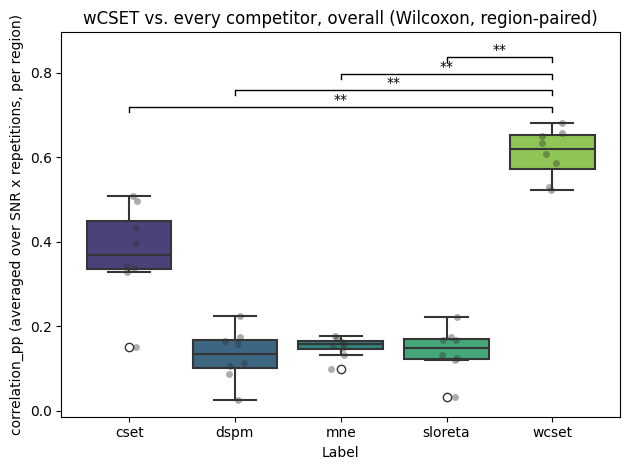

In [7]:
results, fig, ax = suite.compare_methods(
    metric="correlation_pp", reference="wcset", subject_col="region", plot=True,
)
ax.set_ylabel("correlation_pp (averaged over SNR x repetitions, per region)")
ax.set_title("wCSET vs. every competitor, overall (Wilcoxon, region-paired)")
fig.tight_layout()

results

## 📊 - Every competitor vs. wCSET

The same call, looped over every competitor, onto a shared subplot grid -- the
"exploratory sweep across all pairs" pattern from `pilot_noise_cluster_permutation.ipynb`,
now four lines of code instead of a hand-rolled permutation routine.

,competitor,snr_start,snr_end,mass,sign,p_value,significant
0,cset,50,10,15.993957,1,0.015625,True
1,cset,2,1,17.005922,1,0.015625,True
2,dspm,50,1,74.013149,1,0.007812,True
3,mne,50,1,98.974994,1,0.007812,True
4,sloreta,50,1,77.809419,1,0.007812,True


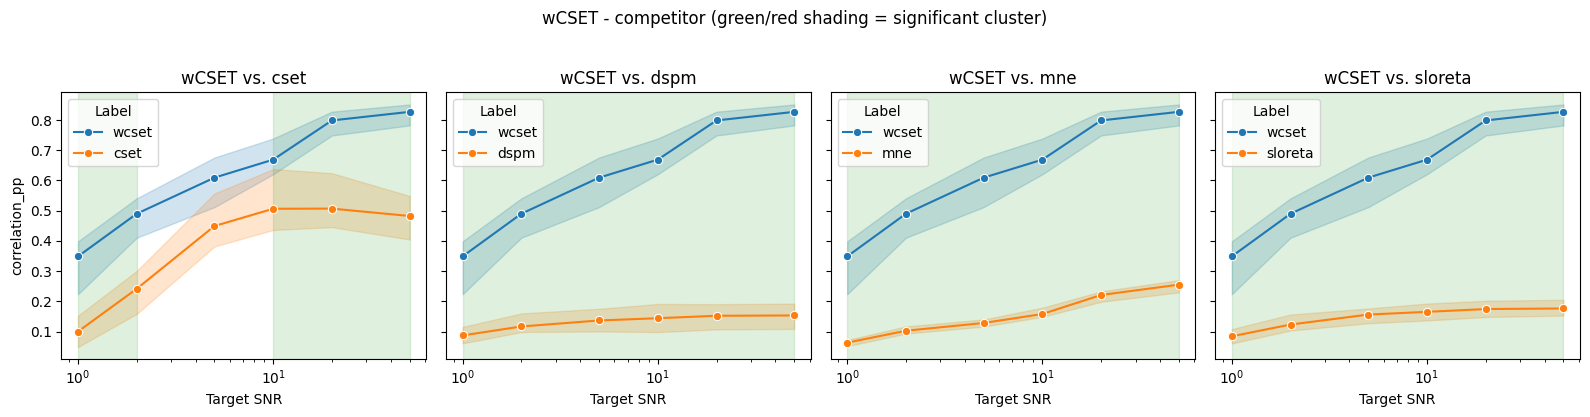

In [8]:
competitors = ["cset", "dspm", "mne", "sloreta"]
snr_order = [50, 20, 10, 5, 2, 1]

fig, axes = plt.subplots(1, len(competitors), figsize=(4 * len(competitors), 4), sharey=True)

all_clusters = []
for ax, competitor in zip(axes, competitors):
    result, _, _ = suite.cluster_permutation(
        metric="correlation_pp", coord="snr", reference="wcset", competitor=competitor,
        subject_col="region", coord_order=snr_order,
        n_permutations=3000, seed=0,
        plot=True, ax=ax, estimator="median", errorbar=("pi", 50), marker="o",
    )
    ax.set_xscale("log")
    ax.set_xlabel("Target SNR")
    ax.set_title(f"wCSET vs. {competitor}")

    clusters = result["clusters"].copy()
    clusters.insert(0, "competitor", competitor)
    all_clusters.append(clusters)

axes[0].set_ylabel("correlation_pp")
fig.suptitle("wCSET - competitor (green/red shading = significant cluster)", y=1.03)
fig.tight_layout()

pd.concat(all_clusters, ignore_index=True)

## 🗜️ - Compact version: every competitor on one axes

The grid above is the most legible way to inspect each pair on its own scale, but a
publication figure often needs the whole comparison in one panel.
`MetricSuite.cluster_permutation_summary` draws every competitor against `wcset` on a
single shared `Axes`, switching each competitor's own segments to a dashed line + open
(white-face) marker wherever they *aren't* significantly worse than `wcset` there,
and a solid line + filled marker where they are -- wCSET itself is always drawn
solid, the fixed baseline everything else reads against. Same test as
`cluster_permutation` above -- the name says so: it's the "every competitor at once"
summary view of the same cluster-permutation family, not a different statistic.

Deliberately not opacity-encoded: an earlier version of this faded the line/band
alpha instead, but two alpha levels on a colored line don't reliably survive
grayscale printing or low-vision viewing. Solid/dashed + filled/open survives color
loss instead.

Each point also carries a thin IQR whisker (`show_spread=True`, the default) --
good research-figure practice is to show uncertainty alongside a significance
verdict, not just the verdict. An earlier version of this dropped spread entirely
after replacing a *continuous, filled* band (which invites misreading "do the
ribbons overlap" as a proxy for significance -- not what this paired, region-level
test actually computes, and got muddy with five overlapping fills); the thin
per-point whisker restores the uncertainty information without either problem,
staying visually subordinate to the line/marker styling that carries the actual
significance result.

`cluster_permutation_mne`'s own cluster p-values are already family-wise corrected
*within* one competitor's swept axis (that's what the cluster-mass permutation null
distribution is for), but calling it once per competitor here means testing
multiple independent families at the nominal `cluster_alpha` with nothing
correcting across them -- the same "one reference vs. several competitors" shape
`compare_methods` already corrects for. `cluster_permutation_summary` pools every
competitor's cluster p-values into one family and FDR-BH corrects across it
(`correction="fdr_bh"`, same default), so the solid/dashed encoding above is driven
by `p_corrected`, not each cluster's raw, uncorrected `p_value`. This is the one
piece of statistics this method adds on top of `cluster_permutation` -- everything
else (the styling, the whiskers) is presentation only.

Pass `colors={...}` (e.g. a project's own fixed method-color mapping) to keep the
legend stable across figures instead of the default `viridis` assignment.

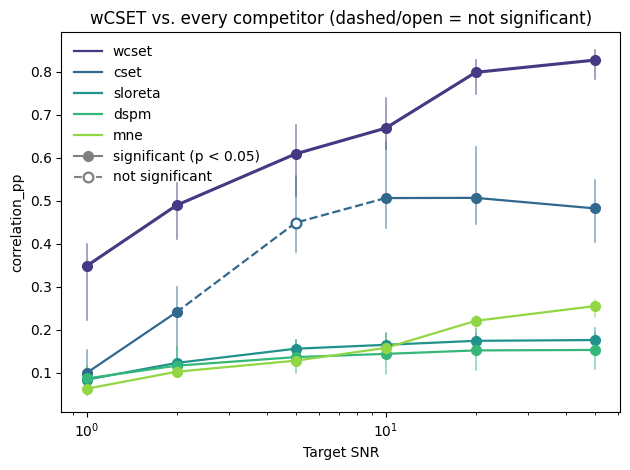

In [9]:
clusters_by_competitor, fig, ax = suite.cluster_permutation_summary(
    metric="correlation_pp", coord="snr", reference="wcset",
    subject_col="region", coord_order=snr_order,
    n_permutations=3000, seed=0, marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("Target SNR")
ax.set_ylabel("correlation_pp")
ax.set_title("wCSET vs. every competitor (dashed/open = not significant)")
fig.tight_layout()

## Wrap-up

- `MetricSuite.load("noisesweep")` -- read the study back from disk.
- `suite.plot(metric=..., x="snr", kind="line", ...)` -- a broad overview across every
  registered method.
- `suite.compare_methods(metric=..., reference=..., plot=True)` -- is a competitor
  significantly different *overall* (collapsed across the whole sweep), via a paired
  Wilcoxon test and an annotated box plot.
- `suite.cluster_permutation(metric=..., coord="snr", reference=..., competitor=...,
  subject_col="region", plot=True)` -- *where along the sweep* a specific pair
  actually differs significantly, with region as the permutation subject.
- `suite.cluster_permutation_summary(metric=..., coord="snr", reference=...,
  subject_col="region")` -- the same sweep-resolved test against every competitor at
  once, condensed onto one publication-compact axes via per-segment line/marker
  styling instead of one subplot per pair.

See `mindmap/metric/base.py` for the full `MetricSuite` API, and
`tutorials/analysis/inverse/inverse-noisesweep.ipynb` for how this study's data was
generated and registered.